# Topology of BERT activations — persistent homology & linking numbers

This notebook fine-tunes (or loads) a BERT classifier, extracts its hidden-state activations on random
subsets of the test set, and studies how their shape evolves layer by layer.

| Section | What it does | Depends on |
|---|---|---|
| **0. Parameters** | The **only** cell you need to edit (dataset, model, number of runs, …) | — |
| **1. Setup** | Imports, parameter checks, shared helpers (projections, multi-run statistics/plots) | 0 |
| **2. Data** | Loads the dataset and builds the train / val / test split | 1 |
| **3. Model** | Builds BERT + classifier, then trains it **or** loads the checkpoint | 2 |
| **4. Activation extraction** | Draws `N_RUNS` random test subsets and extracts their activations | 3 |
| **A. Projection visualisation** | 2D/3D PCA (or MDS, t-SNE) plots of every layer — run 0 | 4 |
| **B. Dimensionality diagnostics** | PCA explained variance and distance-preservation (stress) curves — run 0 | 4 |
| **C. Persistent homology** | C.0 definitions → C.1 barcodes of run 0, C.2 statistics over all runs | 4 |
| **D. Linking number** | D.0 definitions → D.1 statistics over all runs | 4 |

**How to use:** edit cell 0 and choose *Run All*. Sections A–D are independent of each other, so you
can run only the ones you need after sections 0–4. Within C and D, run the `.0` definitions cell first.

**Repeated runs.** Run *r* draws `N_SAMPLES` test examples with seed `SEED + r` and recomputes every
projection on that sample. Each forward pass is computed only once and reused if an example appears in
several runs, which gives the same numbers as extracting each run on its own. Multi-run plots show the
**mean across runs** (thick line), a **±1 std band**, every **individual run** (faint lines), and
optional **box plots**. Tables give mean, std, SEM, 95 % CI, median, min/max and coefficient of
variation. A Spearman-trend table shows how consistently each metric rises or falls with depth.

## 0. Parameters
After editing, re-run this cell **and everything below it**. Sections A–D read their own parameters
when they run. Changes to the dataset, model, `N_RUNS`, `N_SAMPLES`, `SEED`, `POOLING` or
`LAYERS_TO_ANALYZE` require re-running from section 1.

In [ ]:
# =============================================================================
# PARAMETERS — the only cell you should need to edit
# =============================================================================

# ── Dataset & model ──────────────────────────────────────────────────────────
DATASET = 'imdb'      # 'imdb'    : IMDB movie reviews, binary sentiment (Negative / Positive)
                      # 'ag_news' : AG News, 4-class topic (World / Sports / Business / Sci/Tech)
MODEL   = 'uncased'   # 'uncased' : bert-base-uncased (12 layers, 768-d hidden states)
                      # 'mini'    : bert-mini         (4 layers, 256-d hidden states)

# ── File locations (edit only if your files live elsewhere) ─────────────────
MODEL_DIRS  = {'uncased': './bert-base-uncased',   # local HuggingFace model folders
               'mini':    './bert-mini'}
IMDB_CSV    = 'movie_reviews.csv'                   # columns: review, sentiment
AG_NEWS_DIR = 'ag_news'                             # must contain train.csv and test.csv
CHECKPOINTS = {                                     # fine-tuned weights per (MODEL, DATASET)
    ('uncased', 'imdb'):    'checkpoint-uncased-IMDB.pt',
    ('uncased', 'ag_news'): 'checkpoint-uncased-agnews.pt',
    ('mini',    'imdb'):    'checkpoint_mini_IMDB.pt',
    ('mini',    'ag_news'): 'checkpoint_mini_agnews.pt',
}

# ── Training / checkpoint ────────────────────────────────────────────────────
TRAIN_MODEL     = False  # False: load the fine-tuned weights from the checkpoint above.
                         # True : fine-tune from the pretrained weights (slow), then optionally save.
EPOCHS          = 3      # } only used when TRAIN_MODEL = True
LEARNING_RATE   = 2e-5   # }
BATCH_SIZE      = 16     # }
SAVE_CHECKPOINT = False   # } overwrites the checkpoint file when training finishes

# ── Repeated experiments / sampling of the test set ─────────────────────────
N_RUNS    = 5     # how many times the experiments are repeated. Each run draws a fresh random
                  # subset of the test set and recomputes all projections on it.
                  # N_RUNS = 1 reproduces the original single-sample analysis.
N_SAMPLES = 750   # test examples drawn per run
SEED      = 20    # run r uses seed SEED + r (SEED = 20 → run 0 is the sample used originally)

# ── Representation ──────────────────────────────────────────────────────────
POOLING           = 'cls'  # 'cls' : hidden state of the [CLS] token
                           # 'mean': average over all non-padding tokens
LAYERS_TO_ANALYZE = None   # None → every encoder layer 1..L; or a list, e.g. [1, 4, 8, 12]
                           # (0 = embedding layer, before any transformer block)
CORRECT_ONLY      = True   # keep only test examples the model classifies correctly (all analyses)

# ── Projection used by persistent homology (C) and linking number (D) ──────
PROJECTION_METHOD = 'pca'  # 'pca' (default: fast, deterministic) | 'mds' (much slower)
N_PH_DIMS         = 3      # target dimension for persistent homology;
                           # None → PH on the raw activations. Linking always uses 3D.

# ── A. Projection visualisation ─────────────────────────────────────────────
VIZ_METHODS    = ['pca']   # any subset of ['pca', 'mds', 'tsne']
VIZ_COMPONENTS = 2         # 2 or 3

# ── B. Dimensionality diagnostics ───────────────────────────────────────────
MAX_STRESS_DIMS    = 15     # stress curves for 1..MAX_STRESS_DIMS dimensions
COMPUTE_MDS_STRESS = False  # True: also fit MDS for every (layer, dim) pair — several minutes

# ── C. Persistent homology ──────────────────────────────────────────────────
PH_CLASS_SUBSET     = 'all'  # 'all' or one class name, e.g. 'Positive' (IMDB) or 'Sports' (AG News)
FILTRATION_MODE     = 'vr'   # 'vr' : Vietoris–Rips on Euclidean distances
                             # 'knn': Vietoris–Rips on hop distances in a k-NN graph
K_NEIGHBORS         = 2      # k of the k-NN graph (FILTRATION_MODE = 'knn' only)
NORMALIZE_DISTANCES = True   # 'vr' only: divide by the max distance → filtration values in [0, 1]
MAX_HOM_DIM         = 2      # compute H0 … H_MAX_HOM_DIM (H2 is the expensive part)

# ── D. Linking number ───────────────────────────────────────────────────────
K_LINK        = 8    # k of the k-NN graph (6–15 recommended)
EPS_PCT       = 70   # keep edges shorter than ε = this percentile of 1st-NN distances
N_SUB         = 4    # midpoint-quadrature subdivisions per edge in the Gauss integral
MIN_CYCLE_LEN = 4    # discard shorter cycles (likely graph artefacts)
MAX_CYCLES    = 60   # keep at most this many cycles per class (shortest first)
N_LINK_SAMP   = 300  # sub-sample this many points per class before building the graphs

# ── Multi-run plots ─────────────────────────────────────────────────────────
SHOW_INDIVIDUAL_RUNS = True  # faint line for each run behind the mean ± std band
SHOW_BOXPLOTS        = True  # extra figure with the per-layer distribution across runs (needs N_RUNS ≥ 3)

# ── Advanced ────────────────────────────────────────────────────────────────
EXTRACT_BATCH_SIZE = 64  # batch size for activation extraction (lower it if you run out of memory)

## 1. Setup
Imports, parameter checks and settings derived from section 0, plus helpers shared by several sections.

In [2]:
# Requirements: pip install torch transformers scikit-learn scipy numpy pandas matplotlib plotly ripser networkx
import inspect
import itertools
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.colors as pcolors
import plotly.graph_objects as go
import ripser
import torch
import torch.nn as nn
from IPython.display import display
from plotly.subplots import make_subplots
from scipy import stats
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, TSNE
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from torch.utils.data import DataLoader, Dataset, Subset
from transformers import AutoTokenizer, BertModel, get_linear_schedule_with_warmup, BertTokenizer

# ── Fixed dataset properties ─────────────────────────────────────────────────
# Do not change these: the train/val/test split has to match the one used to train the checkpoints.
DATASET_INFO = {
    'imdb':    dict(display_name='IMDB Movie Reviews', max_samples=None,
                    class_names=['Negative', 'Positive']),
    'ag_news': dict(display_name='AG News', max_samples=20000,   # cap on ~127k rows for local training
                    class_names=['World', 'Sports', 'Business', 'Sci/Tech']),
}
SPLIT_SEED = 42    # seed of the dataset sub-sampling and train/val/test split
MAX_LENGTH = 256   # max tokens per text

# ── Parameter checks ────────────────────────────────────────────────────────
def _check(name, value, allowed):
    if value not in allowed:
        raise ValueError(f"{name} = {value!r} is not valid; choose one of {list(allowed)}")

_check('DATASET', DATASET, DATASET_INFO)
_check('MODEL', MODEL, MODEL_DIRS)
_check('POOLING', POOLING, ['cls', 'mean'])
_check('PROJECTION_METHOD', PROJECTION_METHOD, ['pca', 'mds'])
_check('FILTRATION_MODE', FILTRATION_MODE, ['vr', 'knn'])
_check('VIZ_COMPONENTS', VIZ_COMPONENTS, [2, 3])
for _m in VIZ_METHODS:
    _check('VIZ_METHODS entry', _m, ['pca', 'mds', 'tsne'])
if N_RUNS < 1 or N_SAMPLES < 10:
    raise ValueError('N_RUNS must be ≥ 1 and N_SAMPLES ≥ 10')

# ── Derived settings ────────────────────────────────────────────────────────
CLASS_NAMES     = DATASET_INFO[DATASET]['class_names']
NUM_LABELS      = len(CLASS_NAMES)
MODEL_PATH      = MODEL_DIRS[MODEL]
CHECKPOINT_PATH = CHECKPOINTS[(MODEL, DATASET)]
_check('PH_CLASS_SUBSET', PH_CLASS_SUBSET, ['all'] + CLASS_NAMES)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Plot styling ────────────────────────────────────────────────────────────
CLASS_COLORS  = ['#1f77b4', '#ffa500', '#d62728', '#2ca02c'][:NUM_LABELS]
CLASS_SYMBOLS = ['x', 'diamond', 'circle', 'square'][:NUM_LABELS]   # colour-blind friendly
SERIES_COLORS = pcolors.qualitative.Plotly                           # hex colours for multi-run plots
HOM_COLORS    = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

print(f"Dataset: {DATASET_INFO[DATASET]['display_name']} | classes: {CLASS_NAMES}")
print(f"Model:   {MODEL_PATH} | checkpoint: {CHECKPOINT_PATH} | device: {device}")
print(f"Runs:    {N_RUNS} × {N_SAMPLES} test samples (seeds {SEED}…{SEED + N_RUNS - 1}) | "
      f"projection: {PROJECTION_METHOD.upper()}")

c:\Users\hector.balsells\Documents\TFM.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: IMDB Movie Reviews | classes: ['Negative', 'Positive']
Model:   ./bert-base-uncased | checkpoint: checkpoint-uncased-IMDB.pt | device: cpu
Runs:    3 × 750 test samples (seeds 20…22) | projection: PCA


In [3]:
# ── Shared helpers: dimensionality reduction ────────────────────────────────

def make_mds(n_components, seed, n_init=4, max_iter=300):
    """Metric MDS with the classic random SMACOF initialisation, across scikit-learn versions."""
    kwargs = dict(n_components=n_components, random_state=seed, n_init=n_init,
                  max_iter=max_iter, n_jobs=-1)
    if 'init' in inspect.signature(MDS).parameters:   # scikit-learn ≥ 1.8
        kwargs['init'] = 'random'
    return MDS(**kwargs)


def project(X, method, n_components, seed=42):
    """Reduce X (n_samples, n_features) to n_components with 'pca', 'mds' or 'tsne'."""
    if method == 'pca':
        return PCA(n_components=n_components, random_state=seed).fit_transform(X)
    if method == 'mds':
        return make_mds(n_components, seed).fit_transform(X)
    if method == 'tsne':
        perplexity = min(30, max(5, (len(X) - 1) // 3))
        return TSNE(n_components=n_components, random_state=seed,
                    perplexity=perplexity, init='pca').fit_transform(X)
    raise ValueError(method)


# ── Shared helpers: statistics over runs ────────────────────────────────────
# All multi-run results use the layout  data[series][panel] = array of shape (n_runs, n_layers).

def describe_runs(V):
    """Per-layer statistics across runs for an array V of shape (n_runs, n_layers)."""
    V = np.asarray(V, dtype=float)
    n = V.shape[0]
    mean = V.mean(axis=0)
    std  = V.std(axis=0, ddof=1) if n > 1 else np.zeros_like(mean)
    sem  = std / np.sqrt(n)
    half = stats.t.ppf(0.975, n - 1) * sem if n > 1 else np.full_like(mean, np.nan)
    with np.errstate(divide='ignore', invalid='ignore'):
        cv = np.where(mean != 0, std / np.abs(mean), np.nan)
    return dict(mean=mean, std=std, sem=sem, ci95_low=mean - half, ci95_high=mean + half,
                median=np.median(V, axis=0), min=V.min(axis=0), max=V.max(axis=0), cv=cv)


def _rgba(hex_color, alpha):
    r, g, b = pcolors.hex_to_rgb(hex_color)
    return f'rgba({r},{g},{b},{alpha})'


def plot_multirun(data, layers, title, y_titles=None):
    """Mean across runs (line) ± 1 std (band), with the individual runs as faint lines."""
    series = list(data)
    panels = list(data[series[0]])
    x = list(layers)
    fig = make_subplots(rows=1, cols=len(panels), subplot_titles=panels, horizontal_spacing=0.06)

    for si, name in enumerate(series):
        color = SERIES_COLORS[si % len(SERIES_COLORS)]
        for pi, panel in enumerate(panels, start=1):
            V = np.asarray(data[name][panel], dtype=float)
            s = describe_runs(V)
            if V.shape[0] > 1:
                if SHOW_INDIVIDUAL_RUNS:
                    for run_values in V:
                        fig.add_trace(go.Scatter(
                            x=x, y=run_values, mode='lines', line=dict(color=color, width=0.8),
                            opacity=0.3, hoverinfo='skip', showlegend=False, legendgroup=name),
                            row=1, col=pi)
                fig.add_trace(go.Scatter(
                    x=x + x[::-1], y=np.r_[s['mean'] + s['std'], (s['mean'] - s['std'])[::-1]],
                    mode='lines', fill='toself', fillcolor=_rgba(color, 0.2), line=dict(width=0),
                    hoverinfo='skip', showlegend=False, legendgroup=name),
                    row=1, col=pi)
            fig.add_trace(go.Scatter(
                x=x, y=s['mean'], mode='lines+markers', name=name, legendgroup=name,
                showlegend=(pi == 1), line=dict(color=color, width=2.5), marker=dict(size=7),
                customdata=np.c_[s['std'], s['min'], s['max']],
                hovertemplate=('Layer %{x}<br>mean %{y:.4g} ± %{customdata[0]:.3g}'
                               '<br>min %{customdata[1]:.4g} · max %{customdata[2]:.4g}'
                               f'<extra>{name}</extra>')),
                row=1, col=pi)
            if y_titles:
                fig.update_yaxes(title_text=y_titles[pi - 1], row=1, col=pi)

    n_runs = np.asarray(data[series[0]][panels[0]]).shape[0]
    band = ' — line: mean, band: ±1 std' + (', faint: individual runs' if SHOW_INDIVIDUAL_RUNS else '')
    fig.update_xaxes(title_text='Layer', tickmode='array', tickvals=x)
    fig.update_layout(
        title=dict(text=f'{title}<br><sup>{n_runs} run(s){band if n_runs > 1 else ""}</sup>',
                   x=0.5, xanchor='center'),
        height=450, width=max(700, 330 * len(panels) + 200), margin=dict(t=110),
        plot_bgcolor='#f7f7f7', legend=dict(x=1.01, y=1, xanchor='left'))
    fig.show()
    return fig


def boxplot_multirun(data, layers, title):
    """Per-layer distribution across runs (box = IQR, dashed line = mean, diamond = ±1 std)."""
    series = list(data)
    panels = list(data[series[0]])
    n_cols = min(2, len(panels))
    n_rows = -(-len(panels) // n_cols)
    fig = make_subplots(rows=n_rows, cols=n_cols, subplot_titles=panels,
                        horizontal_spacing=0.08, vertical_spacing=0.25 / n_rows)
    for si, name in enumerate(series):
        color = SERIES_COLORS[si % len(SERIES_COLORS)]
        for pi, panel in enumerate(panels):
            V = np.asarray(data[name][panel], dtype=float)
            fig.add_trace(go.Box(
                x=np.tile(list(layers), V.shape[0]), y=V.ravel(), name=name, legendgroup=name,
                offsetgroup=name, showlegend=(pi == 0), marker_color=color, boxmean='sd',
                boxpoints='all', jitter=0.3, pointpos=0, marker_size=3),
                row=pi // n_cols + 1, col=pi % n_cols + 1)
    fig.update_xaxes(title_text='Layer', tickmode='array', tickvals=list(layers))
    fig.update_layout(title=dict(text=f'{title} — distribution across runs', x=0.5, xanchor='center'),
                      boxmode='group', height=420 * n_rows + 80, width=750 * n_cols + 150,
                      plot_bgcolor='#f7f7f7', legend=dict(x=1.01, y=1, xanchor='left'))
    fig.show()
    return fig


def summary_table(data, layers):
    """Long table: one row per (series, metric, layer) with all statistics across runs."""
    rows = []
    for name, panels in data.items():
        for panel, V in panels.items():
            s = describe_runs(V)
            for j, layer in enumerate(layers):
                rows.append({'series': name, 'metric': panel, 'layer': layer,
                             'n_runs': np.asarray(V).shape[0], **{k: v[j] for k, v in s.items()}})
    return pd.DataFrame(rows).set_index(['series', 'metric', 'layer'])


def trend_table(data, layers):
    """Spearman correlation between layer index and metric, computed per run, summarised over runs."""
    rows = []
    for name, panels in data.items():
        for panel, V in panels.items():
            rhos = []
            for run_values in np.asarray(V, dtype=float):
                if len(layers) >= 3 and np.ptp(run_values) > 0:
                    rhos.append(stats.spearmanr(layers, run_values).statistic)
            rhos = np.array(rhos)
            rows.append({'series': name, 'metric': panel,
                         'mean ρ': rhos.mean() if len(rhos) else np.nan,
                         'std ρ': rhos.std(ddof=1) if len(rhos) > 1 else np.nan,
                         '% runs ρ > 0': 100 * (rhos > 0).mean() if len(rhos) else np.nan,
                         'valid runs': len(rhos)})
    return pd.DataFrame(rows).set_index(['series', 'metric'])


def report_multirun(data, layers, title, y_titles=None):
    """Plot + optional box plots + compact 'mean ± std' table + trend table. Returns the full table."""
    plot_multirun(data, layers, title, y_titles)
    n_runs = np.asarray(next(iter(next(iter(data.values())).values()))).shape[0]
    if SHOW_BOXPLOTS and n_runs >= 3:
        boxplot_multirun(data, layers, title)
    table = summary_table(data, layers)
    compact = (table['mean'].map('{:.4g}'.format) + ' ± ' + table['std'].map('{:.3g}'.format))
    print('Mean ± std across runs:')
    display(compact.unstack(['series', 'metric']))
    if n_runs > 1:
        print('Trend with depth (Spearman ρ between layer index and metric, per run):')
        display(trend_table(data, layers).round(3))
    return table

## 2. Data
Loads the selected dataset, keeps a `text` column and an integer `label` column, then builds the
train / validation / test split. The split uses a fixed seed so it matches the stored checkpoints.

In [4]:
def load_imdb(path):
    raw = pd.read_csv(path)
    return pd.DataFrame({'text': raw['review'],
                         'label': raw['sentiment'].map({'negative': 0, 'positive': 1})})


def load_ag_news(folder):
    def read(path):
        # Works with the Kaggle layout (header "Class Index,Title,Description")
        # and with the original Zhang et al. files (same 3 columns, no header).
        raw = pd.read_csv(path)
        if not {'Class Index', 'Title', 'Description'}.issubset(raw.columns):
            raw = pd.read_csv(path, header=None, names=['Class Index', 'Title', 'Description'])
        return raw
    raw = pd.concat([read(f'{folder}/train.csv'), read(f'{folder}/test.csv')], ignore_index=True)
    return pd.DataFrame({'text': raw['Title'].astype(str) + '. ' + raw['Description'].astype(str),
                         'label': raw['Class Index'].astype(int) - 1})     # 1-indexed → 0-indexed


df = load_imdb(IMDB_CSV) if DATASET == 'imdb' else load_ag_news(AG_NEWS_DIR)

max_samples = DATASET_INFO[DATASET]['max_samples']
if max_samples is not None and len(df) > max_samples:
    df = df.sample(n=max_samples, random_state=SPLIT_SEED).reset_index(drop=True)
    print(f"Sub-sampled to {len(df)} rows (max_samples = {max_samples})")

train_df, test_df = train_test_split(df, test_size=0.2, random_state=SPLIT_SEED, stratify=df['label'])
train_df, val_df  = train_test_split(train_df, test_size=0.1, random_state=SPLIT_SEED,
                                     stratify=train_df['label'])


class TextDataset(Dataset):
    """Returns raw (text, label) pairs; tokenisation happens per batch in `collate_fn` (section 3)."""
    def __init__(self, frame):
        self.texts  = frame['text'].tolist()
        self.labels = frame['label'].astype(int).tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx], self.labels[idx]


train_dataset, val_dataset, test_dataset = map(TextDataset, (train_df, val_df, test_df))

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
display(df.head())

Train: 36000 | Val: 4000 | Test: 10000


,text,label
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


## 3. Model
BERT with a linear classification head on the final `[CLS]` token. `output_hidden_states=True` makes
the model also return the embedding output (layer 0) and the output of every encoder layer (1..L).

With `TRAIN_MODEL = False` (default) the fine-tuned weights are loaded from the checkpoint. With
`TRAIN_MODEL = True` the model is fine-tuned and, if `SAVE_CHECKPOINT`, saved in the same format.

In [5]:
class BertClassifierWithActivations(nn.Module):
    def __init__(self, model_path, num_labels, dropout=0.1):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_path, local_files_only=True,
                                              output_hidden_states=True)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        # hidden_states: tuple of L+1 tensors (batch, seq_len, hidden):
        #   [0] embedding output, [1..L] output of each encoder layer
        hidden_states = self.bert(input_ids=input_ids, attention_mask=attention_mask).hidden_states
        logits = self.classifier(self.dropout(hidden_states[-1][:, 0, :]))   # final-layer [CLS]
        return {'logits': logits, 'hidden_states': hidden_states}


tokenizer = BertTokenizer.from_pretrained(MODEL_PATH, local_files_only=True)

def collate_fn(batch):
    """Tokenise a batch, padding only to the longest text in it (much faster than padding to MAX_LENGTH;
    padded positions are masked, so the outputs are the same)."""
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), max_length=MAX_LENGTH, truncation=True, padding=True,
                    return_tensors='pt')
    return {'input_ids': enc['input_ids'], 'attention_mask': enc['attention_mask'],
            'label': torch.tensor(labels, dtype=torch.long)}


torch.manual_seed(SPLIT_SEED)
model  = BertClassifierWithActivations(MODEL_PATH, NUM_LABELS).to(device)
LAYERS = model.bert.config.num_hidden_layers
print(f"Model: {LAYERS} encoder layers, hidden size {model.bert.config.hidden_size}, "
      f"{NUM_LABELS} output classes, on {device}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2133.23it/s]
[transformers] BertModel LOAD REPORT from: ./bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: 12 encoder layers, hidden size 768, 2 output classes, on cpu


In [6]:
def run_epoch(loader, optimizer=None, scheduler=None):
    """One pass over `loader`; trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    loss_fn = nn.CrossEntropyLoss()
    total_loss, correct = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch in loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)
            logits = model(input_ids, attention_mask)['logits']
            loss   = loss_fn(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            total_loss += loss.item()
            correct    += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)


if TRAIN_MODEL:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, collate_fn=collate_fn)
    optimizer    = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps  = len(train_loader) * EPOCHS
    scheduler    = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=total_steps // 10,
                                                   num_training_steps=total_steps)
    for epoch in range(EPOCHS):
        tr_loss, tr_acc = run_epoch(train_loader, optimizer, scheduler)
        vl_loss, vl_acc = run_epoch(val_loader)
        print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {vl_loss:.3f} acc {vl_acc:.3f}")
    if SAVE_CHECKPOINT:
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scheduler_state_dict': scheduler.state_dict(),
                    'val_acc': vl_acc, 'val_loss': vl_loss}, CHECKPOINT_PATH)
        print(f"Saved checkpoint to '{CHECKPOINT_PATH}'")
else:
    try:
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    except FileNotFoundError:
        raise FileNotFoundError(f"No checkpoint at '{CHECKPOINT_PATH}'. "
                                "Set TRAIN_MODEL = True in section 0 to train one.") from None
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded '{CHECKPOINT_PATH}' (epoch {checkpoint.get('epoch', '?')}, "
          f"val_acc = {checkpoint.get('val_acc', float('nan')):.3f})")
model.eval();

Loaded 'checkpoint-uncased-IMDB.pt' (epoch 2, val_acc = 0.924)


## 4. Activation extraction
1. Draws the test-set sample of every run (run *r* uses seed `SEED + r`).
2. Runs the model **once** on the union of all samples and keeps the `POOLING` representation of
   each analysed layer. Activations don't depend on the other examples in a batch, so this gives
   the same values as extracting each run separately, with no repeated forward passes.
3. Provides accessors used by every analysis section:
   - `runs[r]`: seed, labels, predictions and `correct` mask of run *r*
   - `run_activations(r, layer)`: (n_samples, hidden) activations
   - `get_projection(r, layer, method, n_components)`: cached projection fitted on **all** samples of the run
   - `class_mask(r, c)`: samples of class *c* (restricted to correctly classified ones if `CORRECT_ONLY`)

In [7]:
ANALYSIS_LAYERS = list(range(1, LAYERS + 1)) if LAYERS_TO_ANALYZE is None else sorted(LAYERS_TO_ANALYZE)
if not set(ANALYSIS_LAYERS) <= set(range(LAYERS + 1)):
    raise ValueError(f"LAYERS_TO_ANALYZE must be within 0..{LAYERS}")


def extract_activations(dataset, indices, layers, pooling, batch_size):
    """Forward pass over dataset[indices]; returns ({layer: (n, hidden)}, labels, predictions)."""
    loader = DataLoader(Subset(dataset, indices.tolist()), batch_size=batch_size,
                        shuffle=False, collate_fn=collate_fn)
    acts, labels, preds = {l: [] for l in layers}, [], []
    model.eval()
    with torch.inference_mode():
        for b, batch in enumerate(loader, start=1):
            attention_mask = batch['attention_mask'].to(device)
            out = model(batch['input_ids'].to(device), attention_mask)
            preds.append(out['logits'].argmax(dim=1).cpu().numpy())
            labels.append(batch['label'].numpy())
            mask = attention_mask.unsqueeze(-1).float()
            for l in layers:
                hs = out['hidden_states'][l]
                emb = hs[:, 0, :] if pooling == 'cls' else (hs * mask).sum(1) / mask.sum(1)
                acts[l].append(emb.float().cpu().numpy())
            print(f"\r  batch {b}/{len(loader)}", end='')
    print()
    return {l: np.concatenate(v) for l, v in acts.items()}, np.concatenate(labels), np.concatenate(preds)


# 1. Sample of every run
n_test      = len(test_dataset)
n_per_run   = min(N_SAMPLES, n_test)
run_indices = [np.random.default_rng(SEED + r).choice(n_test, size=n_per_run, replace=False)
               for r in range(N_RUNS)]
pool_idx    = np.unique(np.concatenate(run_indices))

# 2. One forward pass over the union of all samples
print(f"Extracting '{POOLING}' activations of layers {ANALYSIS_LAYERS} for {len(pool_idx)} unique "
      f"test examples ({N_RUNS} run(s) × {n_per_run})...")
t0 = time.time()
pool_acts, pool_labels, pool_preds = extract_activations(
    test_dataset, pool_idx, ANALYSIS_LAYERS, POOLING, EXTRACT_BATCH_SIZE)
print(f"Done in {time.time() - t0:.1f}s")

# 3. Per-run views
runs = []
for r, idx in enumerate(run_indices):
    pos = np.searchsorted(pool_idx, idx)          # positions of this run's examples in the pool
    labels, preds = pool_labels[pos], pool_preds[pos]
    runs.append(dict(seed=SEED + r, pos=pos, labels=labels, preds=preds, correct=(labels == preds)))


def run_activations(r, layer):
    return pool_acts[layer][runs[r]['pos']]


def class_mask(r, c=None):
    """Boolean mask over run r: class c (None = every class), correct-only if CORRECT_ONLY."""
    mask = runs[r]['correct'].copy() if CORRECT_ONLY else np.ones(len(runs[r]['labels']), bool)
    if c is not None:
        mask &= runs[r]['labels'] == c
    return mask


_PROJ_CACHE = {}

def get_projection(r, layer, method, n_components):
    """Projection of the activations of run r at `layer`, fitted on all samples of the run (cached).
    n_components=None returns the raw activations."""
    if n_components is None:
        return run_activations(r, layer)
    key = (r, layer, method, n_components)
    if key not in _PROJ_CACHE:
        _PROJ_CACHE[key] = project(run_activations(r, layer), method, n_components, seed=runs[r]['seed'])
    return _PROJ_CACHE[key]


summary = pd.DataFrame([{
    'run': r, 'seed': info['seed'], 'accuracy': info['correct'].mean(),
    **{f'{name} (correct/total)': f"{((info['labels'] == c) & info['correct']).sum()}/"
                                   f"{(info['labels'] == c).sum()}"
       for c, name in enumerate(CLASS_NAMES)}} for r, info in enumerate(runs)]).set_index('run')
display(summary)
print(f"Activation shape per layer and run: {run_activations(0, ANALYSIS_LAYERS[0]).shape}")

Extracting 'cls' activations of layers [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] for 2103 unique test examples (3 run(s) × 750)...
  batch 33/33
Done in 417.5s


,seed,accuracy,Negative (correct/total),Positive (correct/total)
run,,,,
0,20,0.929333,347/377,350/373
1,21,0.925333,323/354,371/396
2,22,0.930667,371/397,327/353


Activation shape per layer and run: (750, 768)


## A. Projection visualisation (run 0)
Layer-by-layer 2D/3D projections of the activations, coloured by class. The methods come from
`VIZ_METHODS`. Only correctly classified samples are shown if `CORRECT_ONLY`.

In [8]:
def axis_limits(coords, pad=0.08):
    lo, hi = coords.min(axis=0), coords.max(axis=0)
    margin = (hi - lo) * pad
    margin[margin == 0] = 1e-3
    return lo - margin, hi + margin


def plot_layer_projections(method, n_components, run=0, point_size=4, opacity=0.7):
    is_3d   = n_components == 3
    n_rows  = len(ANALYSIS_LAYERS)
    Scatter = go.Scatter3d if is_3d else go.Scatter
    fig = make_subplots(rows=n_rows, cols=1,
                        specs=[[{'type': 'scene' if is_3d else 'xy'}] for _ in ANALYSIS_LAYERS],
                        subplot_titles=[f'Layer {l}' for l in ANALYSIS_LAYERS],
                        vertical_spacing=min(0.04, 1 / max(n_rows - 1, 1)))

    for row, l in enumerate(ANALYSIS_LAYERS, start=1):
        coords = get_projection(run, l, method, n_components)
        lo, hi = axis_limits(coords)
        for c, name in enumerate(CLASS_NAMES):
            pts = coords[class_mask(run, c)]
            xyz = dict(x=pts[:, 0], y=pts[:, 1], **({'z': pts[:, 2]} if is_3d else {}))
            fig.add_trace(Scatter(**xyz, mode='markers', name=name, legendgroup=name,
                                  showlegend=(row == 1),
                                  marker=dict(size=point_size, color=CLASS_COLORS[c], opacity=opacity,
                                              symbol=CLASS_SYMBOLS[c], line=dict(width=0))),
                          row=row, col=1)
        if is_3d:
            fig.update_scenes(xaxis=dict(range=[lo[0], hi[0]], title='Dim 1'),
                              yaxis=dict(range=[lo[1], hi[1]], title='Dim 2'),
                              zaxis=dict(range=[lo[2], hi[2]], title='Dim 3'),
                              bgcolor='#f2f2f2', row=row, col=1)
        else:
            fig.update_xaxes(range=[lo[0], hi[0]], title_text='Dim 1', gridcolor='white', row=row, col=1)
            fig.update_yaxes(range=[lo[1], hi[1]], title_text='Dim 2', gridcolor='white', row=row, col=1)

    subset = 'correctly classified only' if CORRECT_ONLY else 'all samples'
    fig.update_layout(height=380 * n_rows, width=700, paper_bgcolor='white', plot_bgcolor='#f2f2f2',
                      title_text=f'{method.upper()} — layer-wise {n_components}D projection '
                                 f'(run {run}, {subset})')
    fig.show()
    return fig


for method in VIZ_METHODS:
    print(f"Computing {method.upper()} projections...")
    plot_layer_projections(method, VIZ_COMPONENTS)

Computing PCA projections...


## B. Dimensionality diagnostics (run 0)
How many dimensions do the activations need?
* **PCA cumulative explained variance** per layer, with the dimensions needed for 90 % / 95 %.
* **Distance-preservation stress** (Kruskal stress-1, `sqrt(Σ(D − D̂)² / ΣD²)`) of a *k*-dimensional
  PCA embedding, and of MDS if `COMPUTE_MDS_STRESS`. Rule of thumb: < 0.10 good, < 0.20 acceptable.
  Both are measured the same way, so the PCA and MDS curves can be compared directly.

In [13]:
RUN = 0
fig_var = go.Figure()
rows = []
for l in ANALYSIS_LAYERS:
    cumvar = np.cumsum(PCA().fit(run_activations(RUN, l)).explained_variance_ratio_) * 100
    rows.append({'layer': l, 'dims for 90%': int(np.searchsorted(cumvar, 90)) + 1,
                 'dims for 95%': int(np.searchsorted(cumvar, 95)) + 1,
                 f'variance in {N_PH_DIMS or 3}D (%)': cumvar[(N_PH_DIMS or 3) - 1]})
    fig_var.add_trace(go.Scatter(x=np.arange(1, len(cumvar) + 1), y=cumvar, mode='lines+markers',
                                 name=f'Layer {l}', marker=dict(size=4)))

fig_var.add_hline(y=90, line_dash='dash', line_color='gray', annotation_text='90%', annotation_position='right')
fig_var.add_hline(y=95, line_dash='dot',  line_color='gray', annotation_text='95%', annotation_position='right')
fig_var.update_layout(title='PCA — cumulative explained variance per layer',
                      xaxis_title='Number of PCA components', yaxis_title='Cumulative explained variance (%)',
                      yaxis_range=[0, 101], width=800, height=500, legend_title='Layer')
fig_var.show()

pca_dims = pd.DataFrame(rows).set_index('layer')
display(pca_dims.round(1))
print(f"Max dims needed for 95% across layers: {pca_dims['dims for 95%'].max()}")

,dims for 90%,dims for 95%,variance in 3D (%)
layer,,,
1,31,50,50.700001
2,41,66,47.700001
3,50,78,52.400002
4,49,76,56.200001


Max dims needed for 95% across layers: 78


In [ ]:
def stress1(D_high, X_low):
    """Kruskal stress-1 between original distances D_high and the distances of embedding X_low."""
    D_low = pairwise_distances(X_low)
    return np.sqrt(((D_high - D_low) ** 2).sum() / (D_high ** 2).sum())


RUN  = 0
dims = list(range(1, MAX_STRESS_DIMS + 1))
fig_stress = go.Figure()
stress_rows = []
for i, l in enumerate(ANALYSIS_LAYERS):
    X = run_activations(RUN, l)
    D = pairwise_distances(X)
    Z = PCA(n_components=min(MAX_STRESS_DIMS, *X.shape)).fit_transform(X)   # PCA embeddings are nested
    curves = {'PCA': [stress1(D, Z[:, :d]) for d in dims if d <= Z.shape[1]]}
    if COMPUTE_MDS_STRESS:
        print(f"  MDS stress, layer {l}...")
        curves['MDS'] = [stress1(D, make_mds(d, SEED, n_init=1, max_iter=200).fit_transform(X)) for d in dims]
    color = SERIES_COLORS[i % len(SERIES_COLORS)]
    for name, values in curves.items():
        fig_stress.add_trace(go.Scatter(x=dims, y=values, mode='lines+markers', name=f'Layer {l} — {name}',
                                        line=dict(color=color, dash='solid' if name == 'PCA' else 'dash'),
                                        marker=dict(size=5)))
        stress_rows += [{'layer': l, 'method': name, 'dims': d, 'stress': s} for d, s in zip(dims, values)]

fig_stress.add_hline(y=0.10, line_dash='dash', line_color='green', annotation_text='Good (0.10)',
                     annotation_position='right')
fig_stress.add_hline(y=0.20, line_dash='dot', line_color='orange', annotation_text='Acceptable (0.20)',
                     annotation_position='right')
fig_stress.update_layout(title='Distance-preservation stress vs number of dimensions'
                               + (' (solid: PCA, dashed: MDS)' if COMPUTE_MDS_STRESS else ' (PCA)'),
                         xaxis_title='Number of dimensions', yaxis_title='Kruskal stress-1',
                         xaxis=dict(tickmode='linear', dtick=1), width=900, height=500)
fig_stress.show()

stress_df = pd.DataFrame(stress_rows)
display(stress_df.pivot_table(index='dims', columns=['method', 'layer'], values='stress').round(3))

## C. Persistent homology
Points: the activations of each layer, projected with `PROJECTION_METHOD` to `N_PH_DIMS` dimensions
(the projection is fitted on the whole run sample), then restricted to `PH_CLASS_SUBSET` and to
correctly classified examples if `CORRECT_ONLY`.
Filtration: Vietoris–Rips on Euclidean distances (`'vr'`, normalised to [0, 1] if
`NORMALIZE_DISTANCES`) or on hop distances of a k-NN graph (`'knn'`).

### C.0 Definitions (run this first)

In [9]:
def knn_hop_distances(X, k):
    """Shortest-path hop counts in the symmetrised k-NN graph (disconnected pairs → max + 1)."""
    graph = kneighbors_graph(X, n_neighbors=k, mode='connectivity', include_self=False)
    D = shortest_path(graph + graph.T, method='D', directed=False, unweighted=True)
    finite = np.isfinite(D)
    D[~finite] = (D[finite].max() if finite.any() else 0.0) + 1.0
    return D


def ph_distance_matrix(X):
    if FILTRATION_MODE == 'knn':
        return knn_hop_distances(X, K_NEIGHBORS)      # already scale-free
    D = pairwise_distances(X)
    if NORMALIZE_DISTANCES and D.max() > 0:
        D = D / D.max()
    return D


def ph_mask(r):
    c = None if PH_CLASS_SUBSET == 'all' else CLASS_NAMES.index(PH_CLASS_SUBSET)
    return class_mask(r, c)


_PH_CACHE = {}

def ph_for_run(r, layer):
    """Persistence diagrams of run r at `layer` (cached, keyed also by the PH parameters)."""
    key = (r, layer, PROJECTION_METHOD, N_PH_DIMS, FILTRATION_MODE, K_NEIGHBORS,
           NORMALIZE_DISTANCES, MAX_HOM_DIM, CORRECT_ONLY, PH_CLASS_SUBSET)
    if key not in _PH_CACHE:
        X = get_projection(r, layer, PROJECTION_METHOD, N_PH_DIMS)[ph_mask(r)]
        dgms = ripser.ripser(ph_distance_matrix(X), distance_matrix=True, maxdim=MAX_HOM_DIM)['dgms']
        _PH_CACHE[key] = dict(dgms=dgms, n_points=len(X),
                              median_dist=float(np.median(pdist(X))))   # scale diagnostic
    return _PH_CACHE[key]


def total_persistence(dgm):
    """Sum of lifetimes (death − birth) over the finite bars of one diagram."""
    finite = dgm[np.isfinite(dgm[:, 1])]
    return float((finite[:, 1] - finite[:, 0]).sum())


HOM_DIMS   = list(range(MAX_HOM_DIM + 1))
PROJ_LABEL = (f'{PROJECTION_METHOD.upper()}-{N_PH_DIMS}' if N_PH_DIMS else 'raw activations')
FILT_LABEL = ('Vietoris–Rips' + (', normalised distances' if NORMALIZE_DISTANCES else '')
              if FILTRATION_MODE == 'vr' else f'{K_NEIGHBORS}-NN hop distances')
SUBSET_LABEL = (('correctly classified ' if CORRECT_ONLY else 'all ')
                + ('samples' if PH_CLASS_SUBSET == 'all' else f'{PH_CLASS_SUBSET} samples'))
print(f"PH on {PROJ_LABEL} | {FILT_LABEL} | {SUBSET_LABEL} | H0..H{MAX_HOM_DIM}")

PH on PCA-3 | Vietoris–Rips, normalised distances | correctly classified samples | H0..H2


### C.1 Barcodes and persistence diagrams (run 0)
One row per layer: barcodes for H0 … H<sub>MAX_HOM_DIM</sub> and a combined persistence diagram.
Dashed bars and triangles are essential (infinite) classes. Barcodes of the same H<sub>k</sub> share the
x-axis range across layers (one range per homology dimension, so short H1/H2 bars stay visible).

  Layer  1: 697 points | H0=697 bars  H1=316 bars  H2= 65 bars
  Layer  2: 697 points | H0=697 bars  H1=339 bars  H2= 61 bars
  Layer  3: 697 points | H0=697 bars  H1=323 bars  H2= 69 bars
  Layer  4: 697 points | H0=697 bars  H1=349 bars  H2= 78 bars
  Layer  5: 697 points | H0=697 bars  H1=349 bars  H2= 69 bars
  Layer  6: 697 points | H0=697 bars  H1=327 bars  H2= 65 bars
  Layer  7: 697 points | H0=697 bars  H1=321 bars  H2= 73 bars
  Layer  8: 697 points | H0=697 bars  H1=312 bars  H2= 51 bars
  Layer  9: 697 points | H0=697 bars  H1=328 bars  H2= 65 bars
  Layer 10: 697 points | H0=697 bars  H1=270 bars  H2= 40 bars
  Layer 11: 697 points | H0=697 bars  H1=275 bars  H2= 24 bars
  Layer 12: 697 points | H0=697 bars  H1=228 bars  H2= 25 bars


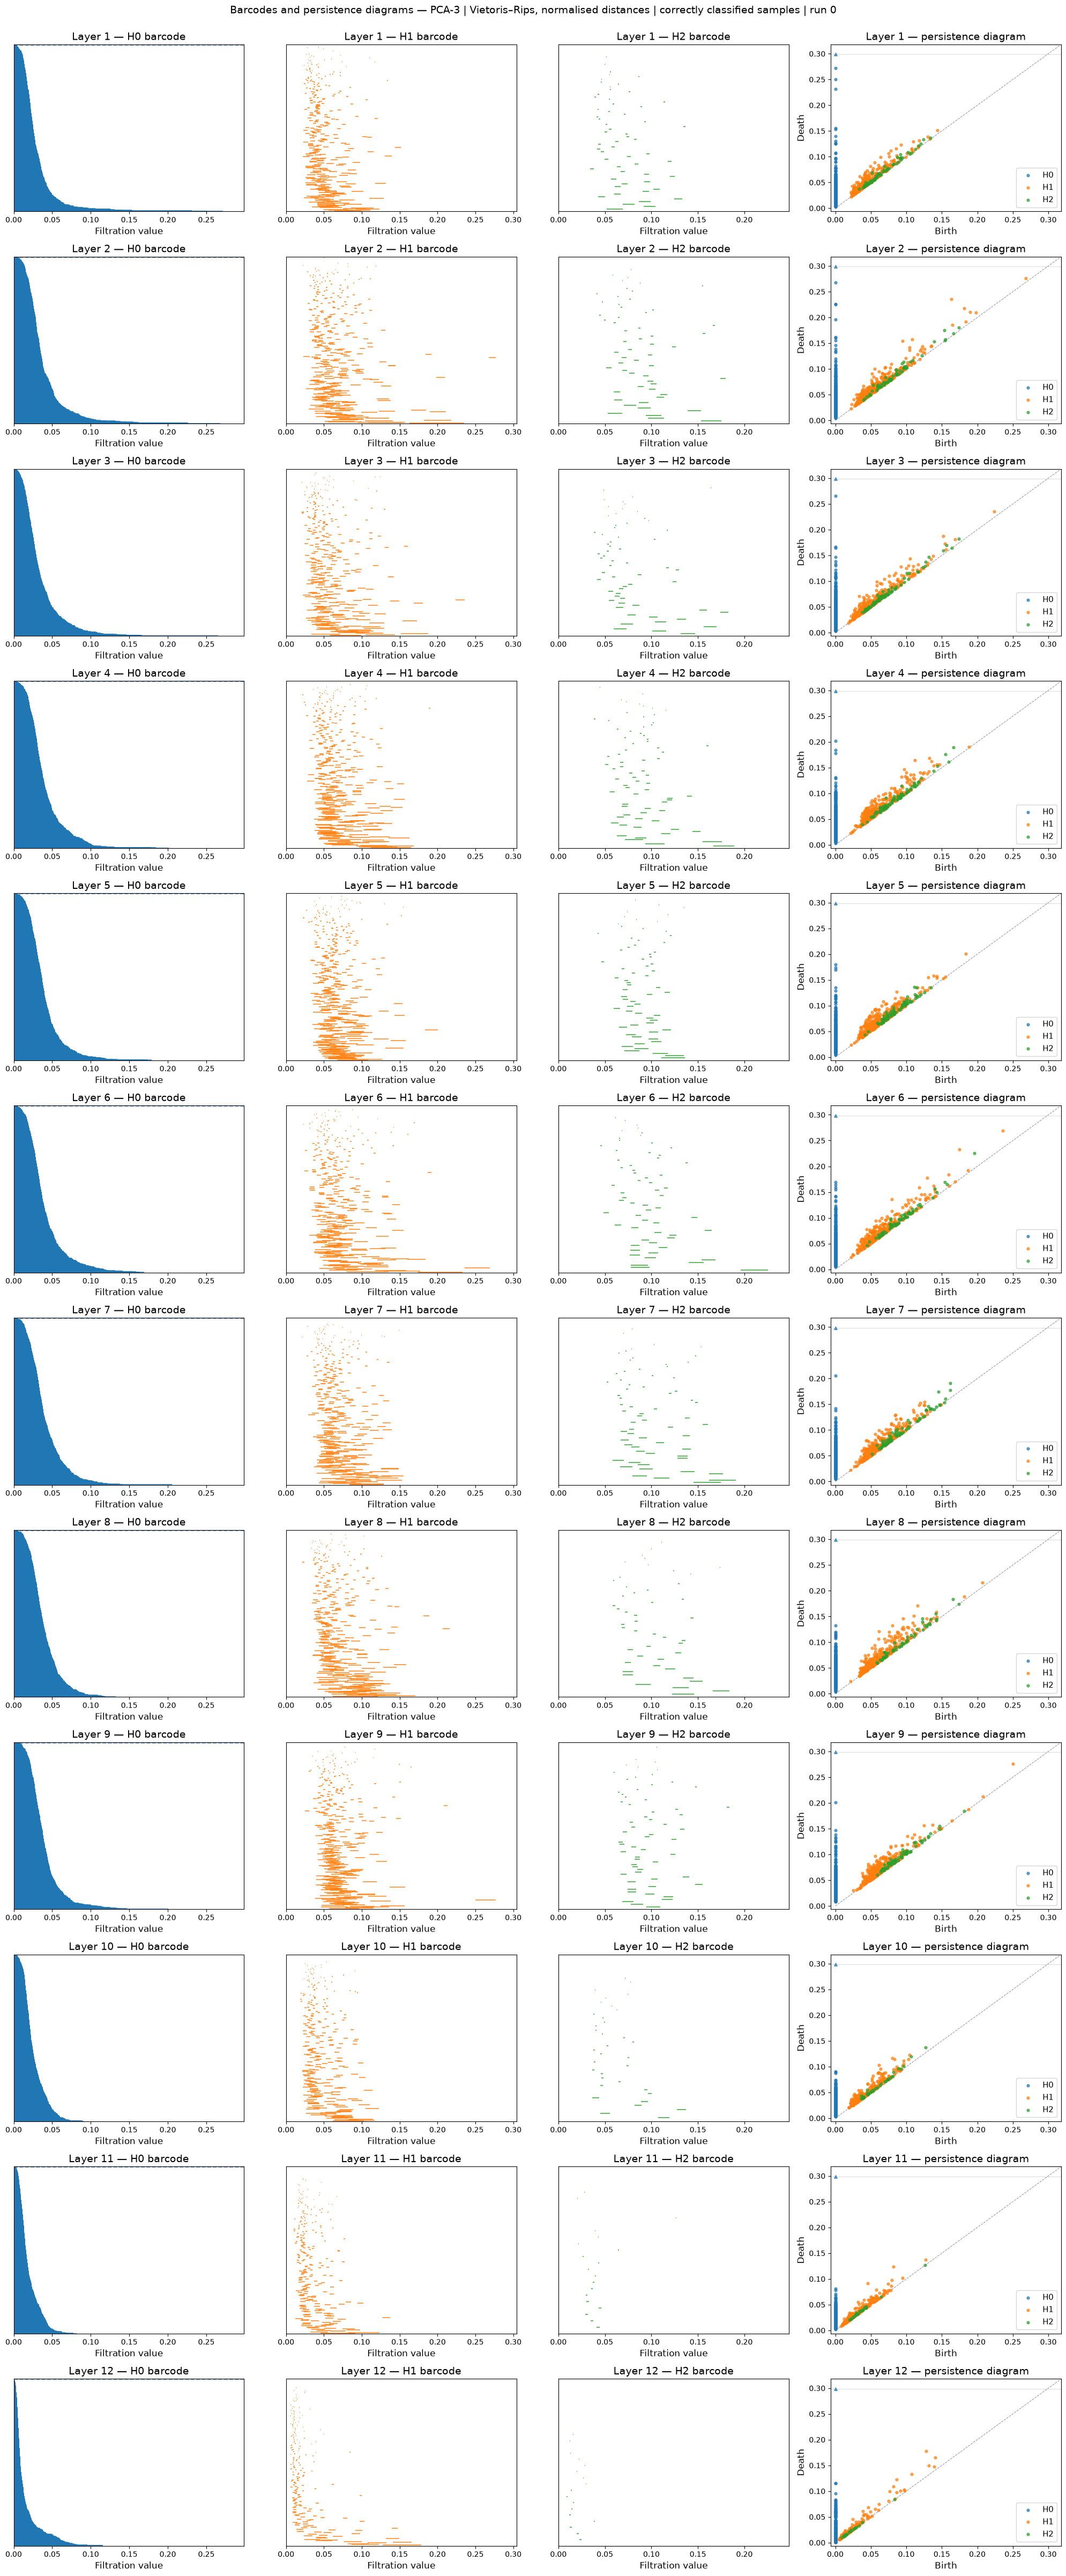

In [10]:
def barcode_ax(ax, dgm, color, title, x_max):
    finite, essential = dgm[np.isfinite(dgm[:, 1])], dgm[~np.isfinite(dgm[:, 1])]
    y = 0
    for b, d in sorted(finite, key=lambda bar: bar[1] - bar[0], reverse=True):   # longest first
        ax.plot([b, d], [y, y], color=color, lw=1.4, alpha=0.75, solid_capstyle='butt')
        y += 1
    for b, _ in essential:
        ax.plot([b, x_max], [y, y], color=color, lw=1.4, alpha=0.75, ls='--', solid_capstyle='butt')
        y += 1
    ax.set_xlim(0, x_max)
    ax.set_ylim(-1, max(y + 1, 2))
    ax.set_yticks([])
    ax.set_xlabel('Filtration value', fontsize=12)
    ax.set_title(title, fontsize=14)


def diagram_ax(ax, dgms, title, top):
    """All homology dimensions on one birth/death plot; essential classes as triangles at the top."""
    hi, ess_y = top * 1.15, top * 1.08
    for dim, dgm in enumerate(dgms):
        finite, essential = dgm[np.isfinite(dgm[:, 1])], dgm[~np.isfinite(dgm[:, 1])]
        color = HOM_COLORS[dim % len(HOM_COLORS)]
        ax.scatter(finite[:, 0], finite[:, 1], c=color, s=12, alpha=0.7, label=f'H{dim}', zorder=3)
        ax.scatter(essential[:, 0], np.full(len(essential), ess_y), c=color, s=16, marker='^',
                   alpha=0.7, zorder=3)
    ax.plot([0, hi], [0, hi], 'k--', lw=0.8, alpha=0.4)
    ax.axhline(ess_y, color='gray', lw=0.5, alpha=0.4)
    ax.set_xlim(-0.02 * hi, hi)
    ax.set_ylim(-0.02 * hi, hi)
    ax.set_xlabel('Birth', fontsize=12)
    ax.set_ylabel('Death', fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.legend(fontsize=11, loc='lower right')


RUN = 0
results_run = {l: ph_for_run(RUN, l) for l in ANALYSIS_LAYERS}
for l, res in results_run.items():
    print(f"  Layer {l:>2}: {res['n_points']} points | "
          + '  '.join(f"H{d}={len(res['dgms'][d]):>3} bars" for d in HOM_DIMS))

# Common scale across layers, one per homology dimension (largest finite death of H_d in any layer),
# so that small H1/H2 bars stay visible next to the long H0 bars.
top_dim = {d: max(res['dgms'][d][np.isfinite(res['dgms'][d][:, 1]), 1].max(initial=0)
                  for res in results_run.values()) or 1.0 for d in HOM_DIMS}
top = max(top_dim.values())

n_cols = len(HOM_DIMS) + 1
fig, axes = plt.subplots(len(ANALYSIS_LAYERS), n_cols, figsize=(5 * n_cols, 4 * len(ANALYSIS_LAYERS)),
                         squeeze=False)
fig.suptitle(f'Barcodes and persistence diagrams — {PROJ_LABEL} | {FILT_LABEL} | {SUBSET_LABEL} | run {RUN}',
             fontsize=14, y=1.0)
for row, l in enumerate(ANALYSIS_LAYERS):
    dgms = results_run[l]['dgms']
    for d in HOM_DIMS:
        barcode_ax(axes[row, d], dgms[d], HOM_COLORS[d % len(HOM_COLORS)], f'Layer {l} — H{d} barcode',
                   x_max=top_dim[d] * 1.1)
    diagram_ax(axes[row, -1], dgms, f'Layer {l} — persistence diagram', top)
plt.tight_layout()
plt.show()

### C.2 Total persistence across runs
For every run (fresh sample, fresh projection) and layer: the total persistence (sum of finite bar
lengths) of each H<sub>k</sub> and of their sum. Also the **median pairwise distance** of the projected
points, as a scale check: with unnormalised VR distances, total persistence grows with the scale of
the point cloud for that reason alone.

Cost: `N_RUNS × layers` persistence computations. H2 on several hundred points takes a while.

In [11]:
n_runs = len(runs)
tp     = {f'H{d}': np.zeros((n_runs, len(ANALYSIS_LAYERS))) for d in HOM_DIMS}
scale  = np.zeros((n_runs, len(ANALYSIS_LAYERS)))

for r in range(n_runs):
    t0 = time.time()
    for j, l in enumerate(ANALYSIS_LAYERS):
        res = ph_for_run(r, l)
        for d in HOM_DIMS:
            tp[f'H{d}'][r, j] = total_persistence(res['dgms'][d])
        scale[r, j] = res['median_dist']
    print(f"Run {r + 1}/{n_runs} (seed {runs[r]['seed']}) done in {time.time() - t0:.1f}s")

tp['+'.join(tp)] = sum(tp[f'H{d}'] for d in HOM_DIMS)    # e.g. 'H0+H1+H2'

ph_data    = {PROJ_LABEL: tp}
ph_summary = report_multirun(ph_data, ANALYSIS_LAYERS,
                             f'Total persistence per layer — {PROJ_LABEL} | {FILT_LABEL} | {SUBSET_LABEL}',
                             y_titles=['Total persistence'] * len(tp))
# ph_summary holds all statistics (mean, std, SEM, 95% CI, median, min, max, CV), e.g.
# ph_summary.to_csv('ph_summary.csv')

Run 1/3 (seed 20) done in 0.0s
Run 2/3 (seed 21) done in 440.6s
Run 3/3 (seed 22) done in 464.2s


Mean ± std across runs:


series          PCA-3                                                   
metric             H0               H1                 H2       H0+H1+H2
layer                                                                   
1        22.75 ± 1.75    2.543 ± 0.236     0.233 ± 0.0403   25.53 ± 2.03
2        26.36 ± 1.32     3.024 ± 0.17     0.297 ± 0.0291    29.68 ± 1.5
3        25.05 ± 1.64    2.729 ± 0.198    0.2699 ± 0.0134   28.05 ± 1.81
4       27.42 ± 0.875    3.386 ± 0.117    0.3863 ± 0.0313   31.19 ± 0.96
5        29.54 ± 1.37   3.444 ± 0.0893    0.3955 ± 0.0361   33.38 ± 1.48
6        28.45 ± 0.31     3.366 ± 0.11    0.3767 ± 0.0511  32.19 ± 0.269
7        29.14 ± 1.35    3.493 ± 0.303    0.4213 ± 0.0327   33.06 ± 1.56
8        26.33 ± 1.51    2.969 ± 0.356    0.2301 ± 0.0254   29.53 ± 1.86
9        27.25 ± 1.03     3.06 ± 0.171    0.2718 ± 0.0168   30.58 ± 1.19
10      18.19 ± 0.432      1.7 ± 0.155    0.0804 ± 0.0186  19.97 ± 0.565
11      13.52 ± 0.347   1.164 ± 0.0166   0.04369 ± 0.0167  14.72 ± 0.348
12       9.914 ± 0.45  0.7773 ± 0.0617  0.02081 ± 0.00306  10.71 ± 0.499

Trend with depth (Spearman ρ between layer index and metric, per run):


mean ρ  std ρ  % runs ρ > 0  valid runs
series metric                                           
PCA-3  H0        -0.429  0.108           0.0           3
       H1        -0.448  0.061           0.0           3
       H2        -0.555  0.073           0.0           3
       H0+H1+H2  -0.443  0.084           0.0           3

In [17]:
# Scale diagnostic: if this grows across layers, unnormalised VR total persistence grows with it.
scale_summary = report_multirun({PROJ_LABEL: {'Median pairwise distance': scale}}, ANALYSIS_LAYERS,
                                f'Median pairwise distance of the projected points — {SUBSET_LABEL}')

Mean ± std across runs:


series,PCA-3
metric,Median pairwise distance
layer,
1,0.9859 ± 0.0144
2,1.052 ± 0.00448
3,2.574 ± 0.029
4,9.516 ± 0.0689


Trend with depth (Spearman ρ between layer index and metric, per run):


,,mean ρ,std ρ,% runs ρ > 0,valid runs
series,metric,,,,
PCA-3,Median pairwise distance,1.0,0.0,100.0,3


## D. Linking number
For every pair of classes and every layer:
1. Project the run's activations to 3D with `PROJECTION_METHOD` (fitted on the whole run sample).
2. Sub-sample `N_LINK_SAMP` points per class (correctly classified only if `CORRECT_ONLY`).
3. Build an ε-filtered k-NN graph per class and take its fundamental cycles (a spanning-tree cycle
   basis), keeping the `MAX_CYCLES` shortest cycles of length ≥ `MIN_CYCLE_LEN`.
4. Compute the Gauss linking integral of every cycle of one class with every cycle of the other,
   rounded to the nearest integer.

Reported per (layer, class pair): **Σ|lk|** total linking, **max|lk|**, **number of linked cycle
pairs** (|lk| ≥ 1), and the **fraction of linked pairs**. The fraction doesn't depend on how many
cycles were found, so it is easier to compare across runs.

### D.0 Definitions (run this first)

In [12]:
def build_filtered_knn_graph(X, k, eps_pct):
    """k-NN graph keeping only edges shorter than ε = eps_pct-th percentile of 1st-NN distances."""
    n = len(X)
    dists, inds = NearestNeighbors(n_neighbors=min(k + 1, n)).fit(X).kneighbors(X)
    eps = np.percentile(dists[:, 1], eps_pct)
    rows, cols = np.nonzero(dists[:, 1:] <= eps)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    G.add_edges_from(zip(rows.tolist(), inds[:, 1:][rows, cols].tolist()))
    return G


def extract_fundamental_cycles(G, X, min_len, max_cycles):
    """Fundamental cycles w.r.t. a BFS spanning forest: each non-tree edge (u, v) closes the unique
    tree path u → v. Returns the coordinates (len_i, 3) of the `max_cycles` shortest cycles."""
    cycles = []
    for comp in nx.connected_components(G):
        if len(comp) < 3:
            continue
        sub  = G.subgraph(comp).copy()
        root = next(iter(comp))
        parent, depth = {}, {root: 0}
        for par, child in nx.bfs_edges(sub, root):
            parent[child], depth[child] = par, depth[par] + 1
        tree_edges = {frozenset(e) for e in parent.items()}
        for u, v in sub.edges():
            if frozenset((u, v)) in tree_edges:
                continue
            a, b, path_a, path_b = u, v, [u], [v]       # climb to the lowest common ancestor
            while depth[a] > depth[b]:
                a = parent[a]; path_a.append(a)
            while depth[b] > depth[a]:
                b = parent[b]; path_b.append(b)
            while a != b:
                a, b = parent[a], parent[b]
                path_a.append(a); path_b.append(b)
            path = path_a + path_b[-2::-1]
            if len(path) >= min_len:
                cycles.append(path)
    cycles.sort(key=len)                                 # shortest = geometrically tightest
    return [X[np.array(c)] for c in cycles[:max_cycles]]


def _cycle_edges(cycles):
    """Concatenate the edges of all cycles: start points, tangents and a (n_cycles, n_edges) indicator."""
    starts   = np.concatenate(cycles)
    tangents = np.concatenate([np.roll(c, -1, axis=0) - c for c in cycles])
    owner    = np.zeros((len(cycles), len(starts)))
    owner[np.repeat(np.arange(len(cycles)), [len(c) for c in cycles]), np.arange(len(starts))] = 1.0
    return starts, tangents, owner


def gauss_linking_matrix(cycles_a, cycles_b, n_sub=4, max_block=2_000_000):
    """Gauss linking integrals  lk(C1, C2) = 1/(4π) ∮∮ (x − y)·(dx × dy) / |x − y|³  for every pair
    (C1 in cycles_a, C2 in cycles_b) of closed polygonal curves in R³, by midpoint quadrature with
    n_sub points per edge. All pairs are computed at once on stacked edges (vectorised)."""
    PA, TA, SA = _cycle_edges(cycles_a)
    PB, TB, SB = _cycle_edges(cycles_b)
    fracs = (np.arange(n_sub) + 0.5) / n_sub
    YB    = PB[None] + fracs[:, None, None] * TB[None]       # quadrature points on B: (n_sub, EB, 3)
    link  = np.zeros((len(cycles_a), len(cycles_b)))
    step  = max(1, max_block // len(PB))                     # limit memory to ~max_block edge pairs
    for s in range(0, len(PA), step):
        sl    = slice(s, s + step)
        cross = np.cross(TA[sl, None, :], TB[None, :, :])     # dx × dy, constant per edge pair
        acc   = np.zeros(cross.shape[:2])
        for f in fracs:
            x = PA[sl] + f * TA[sl]
            for y in YB:
                diff = x[:, None, :] - y[None, :, :]
                d3   = np.einsum('ijk,ijk->ij', diff, diff) ** 1.5
                dots = np.einsum('ijk,ijk->ij', diff, cross)
                with np.errstate(divide='ignore', invalid='ignore'):
                    acc += np.where(d3 > 1e-20, dots / d3, 0.0)
        link += SA[:, sl] @ acc @ SB.T                       # sum edge pairs → cycle pairs
    return link / (4.0 * np.pi * n_sub ** 2)


CLASS_PAIRS  = list(itertools.combinations(range(NUM_LABELS), 2))
LINK_METRICS = {'sum_abs': 'Σ|lk| — total linking', 'max_abs': 'max|lk| — strongest link',
                'n_linked': 'Linked pairs (|lk| ≥ 1)', 'frac_linked': 'Fraction of linked pairs'}


def linking_for_run(r, layer):
    """Linking summary for every class pair of run r at `layer`."""
    X3  = get_projection(r, layer, PROJECTION_METHOD, 3)
    rng = np.random.default_rng(runs[r]['seed'])               # same sub-sample for every layer
    cycles = {}
    for c in range(NUM_LABELS):
        idx = np.flatnonzero(class_mask(r, c))
        idx = rng.choice(idx, min(N_LINK_SAMP, len(idx)), replace=False)
        cycles[c] = ([] if len(idx) < 3 else
                     extract_fundamental_cycles(build_filtered_knn_graph(X3[idx], K_LINK, EPS_PCT),
                                                X3[idx], MIN_CYCLE_LEN, MAX_CYCLES))
    out = {}
    for a, b in CLASS_PAIRS:
        res = dict(beta_a=len(cycles[a]), beta_b=len(cycles[b]), sum_abs=0.0, max_abs=0.0,
                   n_pairs=0, n_linked=0, frac_linked=0.0)
        if cycles[a] and cycles[b]:
            lk = np.abs(np.round(gauss_linking_matrix(cycles[a], cycles[b], N_SUB)))
            res.update(sum_abs=float(lk.sum()), max_abs=float(lk.max()), n_pairs=lk.size,
                       n_linked=int((lk >= 1).sum()), frac_linked=float((lk >= 1).mean()))
        out[(a, b)] = res
    return out

print(f"{len(CLASS_PAIRS)} class pair(s) | {PROJECTION_METHOD.upper()}-3 | k={K_LINK}, ε={EPS_PCT}th pct, "
      f"N_sub={N_SUB}, max β={MAX_CYCLES}, n_samp={N_LINK_SAMP}")

1 class pair(s) | PCA-3 | k=8, ε=70th pct, N_sub=4, max β=60, n_samp=300


### D.1 Linking numbers across runs

In [13]:
n_runs = len(runs)
pair_names = {p: f'{CLASS_NAMES[p[0]]} vs {CLASS_NAMES[p[1]]}' for p in CLASS_PAIRS}
link_data  = {pair_names[p]: {title: np.zeros((n_runs, len(ANALYSIS_LAYERS))) for title in LINK_METRICS.values()}
              for p in CLASS_PAIRS}
link_log   = []                                             # every individual result, for inspection

for r in range(n_runs):
    t0 = time.time()
    for j, l in enumerate(ANALYSIS_LAYERS):
        for pair, res in linking_for_run(r, l).items():
            for key, title in LINK_METRICS.items():
                link_data[pair_names[pair]][title][r, j] = res[key]
            link_log.append({'run': r, 'layer': l, 'pair': pair_names[pair], **res})
    print(f"Run {r + 1}/{n_runs} (seed {runs[r]['seed']}) done in {time.time() - t0:.1f}s")

link_log = pd.DataFrame(link_log)
print("Cycles found per class (β), mean over runs:")
display(link_log.groupby(['pair', 'layer'])[['beta_a', 'beta_b']].mean().unstack('pair').round(1))

link_summary = report_multirun(
    link_data, ANALYSIS_LAYERS,
    f'Gauss linking numbers per layer — {PROJECTION_METHOD.upper()}-3 | k={K_LINK}-NN | '
    f'ε={EPS_PCT}th pct | max β={MAX_CYCLES} | N_sub={N_SUB}')
# link_summary holds all statistics; link_log every individual (run, layer, pair) result.

Run 1/3 (seed 20) done in 1.2s
Run 2/3 (seed 21) done in 0.7s
Run 3/3 (seed 22) done in 0.9s
Cycles found per class (β), mean over runs:


,beta_a,beta_b
pair,Negative vs Positive,Negative vs Positive
layer,,
1,60.0,53.0
2,34.7,60.0
3,60.0,60.0
4,46.0,42.0
5,34.7,22.7
6,28.7,39.3
7,53.7,56.3
8,45.0,31.0


Mean ± std across runs:


series  Negative vs Positive                                                   \
metric Σ|lk| — total linking max|lk| — strongest link Linked pairs (|lk| ≥ 1)   
layer                                                                           
1                 46.67 ± 67                    1 ± 0              46.67 ± 67   
2                  22 ± 10.8            1.667 ± 0.577               18 ± 9.17   
3               20.33 ± 17.5            1.667 ± 0.577              19.33 ± 17   
4              0.6667 ± 1.15           0.3333 ± 0.577           0.6667 ± 1.15   
5             0.3333 ± 0.577           0.3333 ± 0.577          0.3333 ± 0.577   
6               8.667 ± 9.87                    1 ± 0            8.667 ± 9.87   
7               16.33 ± 20.3             1.667 ± 2.08            15.33 ± 18.6   
8               15.33 ± 18.6             1.333 ± 1.53                 10 ± 10   
9                      0 ± 0                    0 ± 0                   0 ± 0   
10                     0 ± 0                    0 ± 0                   0 ± 0   
11                     0 ± 0                    0 ± 0                   0 ± 0   
12                     0 ± 0                    0 ± 0                   0 ± 0   

series                           
metric Fraction of linked pairs  
layer                            
1              0.01341 ± 0.0182  
2             0.01013 ± 0.00573  
3             0.00537 ± 0.00473  
4          0.0002315 ± 0.000401  
5          0.0002499 ± 0.000433  
6            0.008702 ± 0.00698  
7            0.004259 ± 0.00516  
8            0.005748 ± 0.00512  
9                         0 ± 0  
10                        0 ± 0  
11                        0 ± 0  
12                        0 ± 0

Trend with depth (Spearman ρ between layer index and metric, per run):


mean ρ  std ρ  % runs ρ > 0  \
series               metric                                                  
Negative vs Positive Σ|lk| — total linking     -0.671  0.100           0.0   
                     max|lk| — strongest link  -0.638  0.075           0.0   
                     Linked pairs (|lk| ≥ 1)   -0.667  0.107           0.0   
                     Fraction of linked pairs  -0.634  0.136           0.0   

                                               valid runs  
series               metric                                
Negative vs Positive Σ|lk| — total linking              3  
                     max|lk| — strongest link           3  
                     Linked pairs (|lk| ≥ 1)            3  
                     Fraction of linked pairs           3